# 09 · Priorización territorial y ubicación óptima de nuevos canales

| | |
|---|---|
| **Pregunta** | ¿Dónde conviene abrir nuevos canales de atención (cajeros, agentes corresponsales) para cubrir la mayor cantidad de adultos desatendidos, y cómo cambia la decisión si se considera la exposición a lluvia extrema? |
| **Datos** | Brecha de acceso 2025 por distrito (notebook 08); índice de exposición a lluvia extrema (notebook 06); población adulta censo 2025; 14 481 centros poblados INEI con tipo urbano o rural. |
| **Métodos** | Déficit de acceso relativo al acceso esperado; matriz oportunidad × riesgo con análisis de sensibilidad del peso del riesgo (τ de Kendall); problema de máxima cobertura (MCLP; Church y ReVelle, 1974) resuelto de forma exacta por programación lineal entera (CBC) y comparado con la heurística voraz; sensibilidad al radio de cobertura. |
| **Salidas** | `outputs/figuras/09_*.png` · `outputs/tablas/09_*.csv` · `data/processed/priorizacion_distrital.csv`. |

**Definiciones.**

* **Adultos desatendidos** del distrito d: A_d · (1 − tasa observada / tasa esperada) si la brecha es negativa, y 0 en otro caso.
  Es la población adulta que quedaría cubierta si el distrito alcanzara el acceso de distritos de estructura similar.
* **Riesgo climático:** índice de exposición a lluvia extrema (z promedio de marzo de 1998, 2017 y 2023), expresado en percentil.
* **Cobertura:** un centro poblado está cubierto si un canal nuevo queda a 5 km o menos en línea recta, una distancia
  razonable para un agente corresponsal en zona rural.

In [1]:
from pathlib import Path
import time
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp
from scipy.spatial import cKDTree
from scipy.stats import kendalltau

warnings.filterwarnings("ignore")
t0 = time.time()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
CRS = "EPSG:32717"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Oportunidad y riesgo por distrito

In [2]:
leer = lambda f: pd.read_csv(DATA / f, dtype={"ubigeo": str})
base = leer("base_aede.csv")
brecha = leer("brecha_acceso_2025.csv")
lluvia = leer("lluvia_extrema_distrito.csv")
distritos = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS)
departamentos = distritos.dissolve("departamento").reset_index()

d = (base[["ubigeo", "distrito", "provincia", "departamento", "pob_18mas", "pob_total_2025", "pob_urbana",
           "lat_capital", "lon_capital"]]
     .merge(brecha[["ubigeo", "tasa_obs", "tasa_esperada", "brecha"]], on="ubigeo")
     .merge(lluvia[["ubigeo", "indice_exposicion"]], on="ubigeo"))
d["desatendido"] = d.brecha < 0
d["adultos_desatendidos"] = np.where(d.desatendido, d.pob_18mas * (1 - d.tasa_obs / d.tasa_esperada), 0.0)
d["canales_faltantes"] = np.where(d.desatendido, (d.tasa_esperada - d.tasa_obs) * d.pob_18mas / 1e4, 0.0)
d["riesgo_pct"] = d.indice_exposicion.rank(pct=True)

des = d[d.desatendido].copy()
des["oportunidad_pct"] = des.adultos_desatendidos.rank(pct=True)
print(f"Distritos desatendidos: {len(des)} de {len(d)}")
print(f"Adultos desatendidos: {des.adultos_desatendidos.sum():,.0f} | canales faltantes: {des.canales_faltantes.sum():,.0f}")
des.nlargest(8, "adultos_desatendidos")[["distrito", "provincia", "tasa_obs", "tasa_esperada",
                                         "adultos_desatendidos", "canales_faltantes", "riesgo_pct"]].round(2)

Distritos desatendidos: 147 de 327
Adultos desatendidos: 768,023 | canales faltantes: 9,466


,distrito,provincia,tasa_obs,tasa_esperada,adultos_desatendidos,canales_faltantes,riesgo_pct
258,VEINTISEIS DE OCTUBRE,PIURA,59.49,159.35,96815.39,1542.79,0.12
250,CASTILLA,PIURA,92.81,163.81,62631.88,1025.97,0.18
138,ALTO TRUJILLO,TRUJILLO,10.48,87.79,58795.23,516.14,0.03
302,PARIÑAS,TALARA,82.88,229.37,47625.77,1092.38,0.40
277,CHULUCANAS,MORROPON,80.87,149.81,31866.21,477.40,0.76
287,PAITA,PAITA,96.70,145.89,25938.83,378.42,0.22
257,TAMBO GRANDE,PIURA,125.45,166.77,25457.93,424.56,0.87
7,LOS BAÑOS DEL INCA,CAJAMARCA,73.24,115.33,17392.37,200.58,0.51


### Matriz oportunidad × riesgo

Los cuadrantes se cortan en la mediana de cada eje entre los distritos desatendidos. La lectura operativa es distinta
en cada uno: alta oportunidad y bajo riesgo admite canales físicos convencionales; alta oportunidad y alto riesgo
pide canales que toleren interrupciones (agentes en comercios con respaldo digital, cajeros en zonas no inundables).

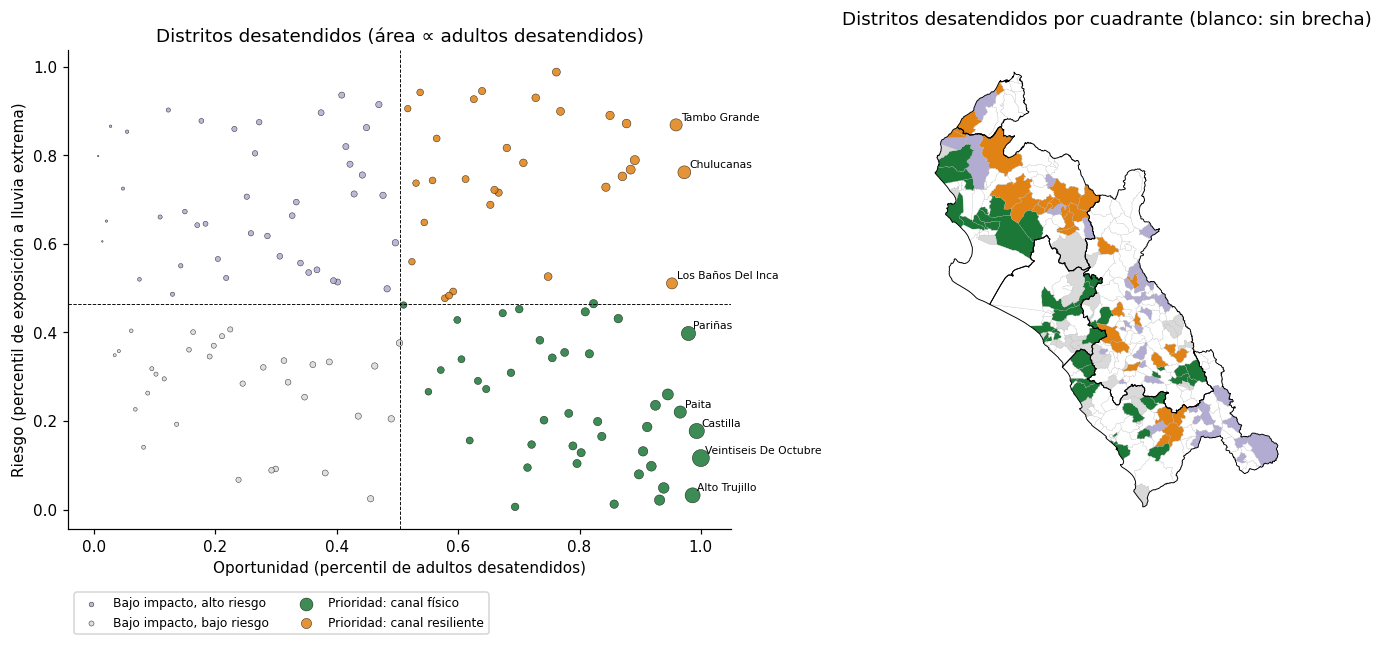

,distritos,adultos_desatendidos
cuadrante,,
"Bajo impacto, alto riesgo",42,43388.0
"Bajo impacto, bajo riesgo",32,30392.0
Prioridad: canal físico,42,509783.0
Prioridad: canal resiliente,31,184459.0


In [3]:
mo, mr = des.oportunidad_pct.median(), des.riesgo_pct.median()
cuad = np.select([(des.oportunidad_pct > mo) & (des.riesgo_pct <= mr), (des.oportunidad_pct > mo) & (des.riesgo_pct > mr),
                  (des.oportunidad_pct <= mo) & (des.riesgo_pct > mr)],
                 ["Prioridad: canal físico", "Prioridad: canal resiliente", "Bajo impacto, alto riesgo"],
                 "Bajo impacto, bajo riesgo")
des["cuadrante"] = cuad
COL = {"Prioridad: canal físico": "#1b7837", "Prioridad: canal resiliente": "#e08214",
       "Bajo impacto, alto riesgo": "#b2abd2", "Bajo impacto, bajo riesgo": "#d9d9d9"}
resumen_cuad = des.groupby("cuadrante").agg(distritos=("ubigeo", "size"),
                                            adultos_desatendidos=("adultos_desatendidos", "sum")).round(0)

fig, axs = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
for k, g in des.groupby("cuadrante"):
    ax.scatter(g.oportunidad_pct, g.riesgo_pct, s=np.sqrt(g.adultos_desatendidos) / 2.5, c=COL[k], label=k,
               edgecolor="k", lw=0.3, alpha=0.85)
ax.axvline(mo, color="k", lw=0.6, ls="--"); ax.axhline(mr, color="k", lw=0.6, ls="--")
for _, r in des.nlargest(8, "adultos_desatendidos").iterrows():
    ax.annotate(r.distrito.title(), (r.oportunidad_pct, r.riesgo_pct), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Oportunidad (percentil de adultos desatendidos)", ylabel="Riesgo (percentil de exposición a lluvia extrema)",
       title="Distritos desatendidos (área ∝ adultos desatendidos)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
m = distritos.merge(des[["ubigeo", "cuadrante"]], on="ubigeo", how="left")
m["color"] = m.cuadrante.map(COL).fillna("white")
m.plot(color=m.color, ax=axs[1], edgecolor="0.7", lw=0.15)
departamentos.boundary.plot(ax=axs[1], color="k", lw=0.6)
axs[1].set_axis_off(); axs[1].set_title("Distritos desatendidos por cuadrante (blanco: sin brecha)")
plt.tight_layout(); plt.savefig(FIG / "09_matriz_oportunidad_riesgo.png", bbox_inches="tight"); plt.show()
resumen_cuad

### Sensibilidad del ranking al peso del riesgo

Score = percentil de oportunidad − λ · percentil de riesgo. Con λ = 0 se ignora el clima; con λ = 1 pesa igual que
la oportunidad. Se mide cuánto cambia el orden (τ de Kendall frente a λ = 0) y cuántos distritos del top 20 se mantienen.

In [4]:
LAMBDAS = [0, 0.25, 0.5, 1.0]
for lam in LAMBDAS:
    des[f"score_l{lam}"] = des.oportunidad_pct - lam * des.riesgo_pct
top0 = set(des.nlargest(20, "score_l0").ubigeo)
sens = pd.DataFrame([{"lambda": lam,
                      "tau_kendall_vs_0": kendalltau(des.score_l0, des[f"score_l{lam}"])[0],
                      "top20_comunes": len(top0 & set(des.nlargest(20, f"score_l{lam}").ubigeo))} for lam in LAMBDAS])
sens.round(3)

,lambda,tau_kendall_vs_0,top20_comunes
0,0.00,1.000,20
1,0.25,0.868,15
2,0.50,0.755,14
3,1.00,0.575,12


## 2. Dos problemas distintos: densificar la ciudad y cubrir el campo

El déficit tiene dos componentes con soluciones distintas. En la ciudad la población ya está a pocos minutos de un
canal; lo que falta es **capacidad** (más cajeros y agentes en el mismo lugar), y un problema de ubicación por
cobertura no aporta, porque cualquier punto cubre a casi todos. En el campo el problema es de **distancia**: la
pregunta es dónde poner pocos canales para que la mayor cantidad de población rural tenga uno cerca. Por eso el
déficit se separa según la fracción urbana del distrito (censo 2025):

* **Densificación urbana:** canales faltantes × fracción urbana, reportados por distrito.
* **Cobertura rural:** adultos desatendidos × fracción rural, repartidos en partes iguales entre los centros poblados
  rurales del distrito (la base no trae población por centro poblado). Esta es la demanda del modelo de ubicación.

In [5]:
des["frac_urbana"] = (des.pob_urbana / des.pob_total_2025).clip(0, 1)
des["canales_urbanos_faltantes"] = des.canales_faltantes * des.frac_urbana
des["adultos_rurales_desatendidos"] = des.adultos_desatendidos * (1 - des.frac_urbana)
print(f"Canales urbanos faltantes: {des.canales_urbanos_faltantes.sum():,.0f} | "
      f"adultos rurales desatendidos: {des.adultos_rurales_desatendidos.sum():,.0f}")
des.nlargest(10, "canales_urbanos_faltantes")[["distrito", "provincia", "departamento", "canales_urbanos_faltantes",
                                               "riesgo_pct", "cuadrante"]].round(2)

Canales urbanos faltantes: 7,777 | adultos rurales desatendidos: 234,273


,distrito,provincia,departamento,canales_urbanos_faltantes,riesgo_pct,cuadrante
258,VEINTISEIS DE OCTUBRE,PIURA,PIURA,1522.50,0.12,Prioridad: canal físico
302,PARIÑAS,TALARA,PIURA,1070.84,0.40,Prioridad: canal físico
250,CASTILLA,PIURA,PIURA,1005.49,0.18,Prioridad: canal físico
138,ALTO TRUJILLO,TRUJILLO,LA LIBERTAD,498.30,0.03,Prioridad: canal físico
277,CHULUCANAS,MORROPON,PIURA,425.94,0.76,Prioridad: canal resiliente
287,PAITA,PAITA,PIURA,373.10,0.22,Prioridad: canal físico
257,TAMBO GRANDE,PIURA,PIURA,263.85,0.87,Prioridad: canal resiliente
222,PIMENTEL,CHICLAYO,LAMBAYEQUE,177.41,0.26,Prioridad: canal físico
216,LA VICTORIA,CHICLAYO,LAMBAYEQUE,154.54,0.02,Prioridad: canal físico
251,CATACAOS,PIURA,PIURA,141.84,0.13,Prioridad: canal físico


## 3. Ubicación óptima en el campo: problema de máxima cobertura (MCLP)

**Formulación** (Church y ReVelle, 1974). Con w_i la demanda del centro poblado rural i, x_j = 1 si se abre un canal
en el candidato j, y_i = 1 si i queda cubierto y N_i los candidatos a 5 km o menos de i:

max Σ w_i y_i   sujeto a   y_i ≤ Σ_{j ∈ N_i} x_j,   Σ x_j = P,   x_j ∈ {0, 1},   0 ≤ y_i ≤ 1.

Todos los centros poblados (urbanos y rurales) de distritos desatendidos son candidatos, porque un canal en un
pueblo urbano puede atender a los caseríos de alrededor. Se resuelve exacto con CBC y se compara con la
heurística voraz, que garantiza al menos 1 − 1/e ≈ 63% del óptimo.

In [6]:
cp = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="centros_poblados").to_crs(CRS)
cp = cp.rename(columns={"inei_distrito": "ubigeo"})[["ubigeo", "ccpp", "tipo", "geometry"]]
cp = cp[cp.ubigeo.isin(des.ubigeo)]
sin_cp = des[~des.ubigeo.isin(cp.ubigeo)]
# Sin capital georreferenciada (distritos de creación reciente) se usa un punto interior del polígono
pts = distritos.set_index("ubigeo").loc[sin_cp.ubigeo].geometry.representative_point()
capitales = gpd.GeoDataFrame({"ubigeo": sin_cp.ubigeo.values, "ccpp": (sin_cp.distrito + " (capital)").values,
                              "tipo": "Urban"}, geometry=pts.values, crs=CRS)
cp = pd.concat([cp, capitales], ignore_index=True)
cp = cp.merge(des[["ubigeo", "distrito", "provincia", "departamento", "adultos_rurales_desatendidos",
                   "riesgo_pct", "cuadrante"]], on="ubigeo")
n_rur = cp[cp.tipo == "Rural"].groupby("ubigeo").size()
cp["demanda"] = np.where(cp.tipo == "Rural", cp.adultos_rurales_desatendidos / cp.ubigeo.map(n_rur), 0.0)
cp["demanda"] = cp.demanda.fillna(0)
print(f"Candidatos: {len(cp):,} centros poblados | con demanda rural: {(cp.demanda > 0).sum():,}")
print(f"Demanda rural asignada: {cp.demanda.sum():,.0f} adultos "
      f"(control: {des.loc[des.ubigeo.isin(n_rur.index), 'adultos_rurales_desatendidos'].sum():,.0f})")

XY = np.c_[cp.geometry.x, cp.geometry.y]
ARBOL = cKDTree(XY)

def vecinos(radio_m):
    return [np.array(v) for v in ARBOL.query_ball_point(XY, radio_m)]

def mclp_exacto(w, N, P):
    n = len(w)
    prob = pulp.LpProblem("MCLP", pulp.LpMaximize)
    x = pulp.LpVariable.dicts("x", range(n), cat="Binary")
    y = pulp.LpVariable.dicts("y", range(n), lowBound=0, upBound=1)
    prob += pulp.lpSum(w[i] * y[i] for i in range(n))
    prob += pulp.lpSum(x.values()) == P
    for i in range(n):
        prob += y[i] <= pulp.lpSum(x[j] for j in N[i])
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=60))
    sel = [j for j in range(n) if x[j].value() > 0.5]
    return sel, pulp.LpStatus[prob.status]

def cubiertos(sel, N):
    cov = np.zeros(len(N), bool)
    for j in sel:
        cov[N[j]] = True          # la cobertura es simétrica (distancia euclidiana)
    return cov

def mclp_voraz(w, N, P):
    cov = np.zeros(len(w), bool); sel = []
    for _ in range(P):
        gan = np.array([w[v][~cov[v]].sum() for v in N])
        j = int(gan.argmax()); sel.append(j); cov[N[j]] = True
    return sel

Candidatos: 6,241 centros poblados | con demanda rural: 5,860
Demanda rural asignada: 232,136 adultos (control: 232,136)


In [7]:
N5 = vecinos(5000)
w = cp.demanda.values; W = w.sum()
filas, soluciones = [], {}
for P in [10, 25, 50]:
    sel, estado = mclp_exacto(w, N5, P); soluciones[P] = sel
    sg = mclp_voraz(w, N5, P)
    filas.append({"P": P, "estado": estado, "cobertura_exacta_%": 100 * w[cubiertos(sel, N5)].sum() / W,
                  "cobertura_voraz_%": 100 * w[cubiertos(sg, N5)].sum() / W,
                  "adultos_cubiertos": w[cubiertos(sel, N5)].sum()})
comparacion = pd.DataFrame(filas)

# Curva de cobertura con la heurística voraz (casi óptima, ver tabla)
voraz_100 = mclp_voraz(w, N5, 100)
curva = [100 * w[cubiertos(voraz_100[:k], N5)].sum() / W for k in range(1, 101)]
print(f"Tiempo acumulado: {time.time() - t0:.0f} s")
comparacion.round(2)

Tiempo acumulado: 12 s


,P,estado,cobertura_exacta_%,cobertura_voraz_%,adultos_cubiertos
0,10,Optimal,14.13,14.10,32799.69
1,25,Optimal,27.42,27.39,63643.44
2,50,Optimal,42.69,41.93,99102.80


### Sensibilidad al radio y escenario ajustado por riesgo

In [8]:
P = 25
def coincidencia(sel_a, sel_b, tol_m=5000):
    """Sitios de B a <= tol de algún sitio de A (soluciones alternativas suelen diferir en pueblos vecinos)."""
    d, _ = cKDTree(XY[sel_a]).query(XY[sel_b])
    return int((d <= tol_m).sum())

radios = []
for r_km in [3, 5, 10]:
    Nr = vecinos(r_km * 1000)
    sel, _ = mclp_exacto(w, Nr, P)
    radios.append({"radio_km": r_km, "cobertura_%": 100 * w[cubiertos(sel, Nr)].sum() / W,
                   "sitios_identicos_a_5km": len(set(sel) & set(soluciones[P])),
                   "sitios_a_5km_de_la_base": coincidencia(soluciones[P], sel)})
radios = pd.DataFrame(radios)

# Escenario con riesgo: la demanda en zonas expuestas se descuenta hasta 50%
w_r = w * (1 - 0.5 * cp.riesgo_pct.values)
sel_r, _ = mclp_exacto(w_r, N5, P)
alto = cp.riesgo_pct.values > 0.75
def perfil(sel, nombre):
    cov = cubiertos(sel, N5)
    return {"escenario": nombre, "cobertura_%": 100 * w[cov].sum() / W,
            "sitios_en_riesgo_alto": int(alto[sel].sum()),
            "riesgo_medio_sitios_pct": cp.riesgo_pct.values[sel].mean() * 100}
escenarios = pd.DataFrame([perfil(soluciones[P], "Sin riesgo"), perfil(sel_r, "Ajustado por riesgo")])
escenarios["sitios_identicos"] = [np.nan, len(set(sel_r) & set(soluciones[P]))]
escenarios["sitios_a_5km_de_la_base"] = [np.nan, coincidencia(soluciones[P], sel_r)]
display(radios.round(2)); escenarios.round(2)

,radio_km,cobertura_%,sitios_identicos_a_5km,sitios_a_5km_de_la_base
0,3,16.33,1,23
1,5,27.42,25,25
2,10,49.74,0,15


,escenario,cobertura_%,sitios_en_riesgo_alto,riesgo_medio_sitios_pct,sitios_identicos,sitios_a_5km_de_la_base
0,Sin riesgo,27.42,8,57.16,NaN,NaN
1,Ajustado por riesgo,27.01,5,48.81,18.0,20.0


In [9]:
sel = soluciones[P]
cov = cubiertos(sel, N5)
sitios = cp.iloc[sel].copy()
sitios["demanda_cubierta"] = [w[N5[j]][:].sum() for j in sel]   # demanda en su radio (puede solaparse)
sitios["en_solucion_con_riesgo"] = [j in set(sel_r) for j in sel]
sitios = sitios.sort_values("demanda_cubierta", ascending=False)
sitios_wgs = sitios.to_crs(4326)
salida = pd.DataFrame({"ccpp": sitios.ccpp, "tipo": sitios.tipo, "distrito": sitios.distrito,
                       "provincia": sitios.provincia, "departamento": sitios.departamento,
                       "lat": sitios_wgs.geometry.y.round(5), "lon": sitios_wgs.geometry.x.round(5),
                       "demanda_en_radio": sitios.demanda_cubierta.round(0), "riesgo_pct": sitios.riesgo_pct.round(2),
                       "cuadrante": sitios.cuadrante, "se_mantiene_con_riesgo": sitios.en_solucion_con_riesgo})
salida.to_csv(TAB / "09_sitios_mclp_P25.csv", index=False)
pd.concat([comparacion, ], axis=0).to_csv(TAB / "09_mclp_exacto_vs_voraz.csv", index=False)
salida.head(12)

,ccpp,tipo,distrito,provincia,departamento,lat,lon,demanda_en_radio,riesgo_pct,cuadrante,se_mantiene_con_riesgo
128,SHAULLO GRANDE,Rural,LLACANORA,CAJAMARCA,CAJAMARCA,-7.17542,-78.41833,5061.0,0.38,Prioridad: canal físico,True
5792,CHUNGAYO,Rural,SANTO DOMINGO,MORROPON,PIURA,-5.05659,-79.88882,4170.0,0.93,Prioridad: canal resiliente,True
423,FARO BAJO,Rural,SOROCHUCO,CELENDIN,CAJAMARCA,-6.92647,-78.27613,3447.0,0.53,Prioridad: canal resiliente,True
171,QUINUAPATA,Rural,LOS BAÑOS DEL INCA,CAJAMARCA,CAJAMARCA,-7.10738,-78.48607,3077.0,0.51,Prioridad: canal resiliente,True
3813,LAS PALMERAS DE LA JOYITA,Urban,PIMENTEL,CHICLAYO,LAMBAYEQUE,-6.80597,-79.88288,3041.0,0.26,Prioridad: canal físico,True
5666,SAN LORENZO,Rural,CHALACO,MORROPON,PIURA,-5.07043,-79.79845,2888.0,0.90,Prioridad: canal resiliente,True
3261,LA RINCONADA,Rural,MOLLEBAMBA,SANTIAGO DE CHUCO,LA LIBERTAD,-8.15783,-77.97338,2871.0,0.54,"Bajo impacto, alto riesgo",True
265,PUEBLO LIBRE,Rural,SAN JUAN,CAJAMARCA,CAJAMARCA,-7.28619,-78.49857,2858.0,0.43,Prioridad: canal físico,True
5095,SALALA,Rural,EL CARMEN DE LA FRONTERA,HUANCABAMBA,PIURA,-5.11041,-79.46321,2798.0,0.77,Prioridad: canal resiliente,True
3655,CHANCHAMAYO,Rural,SAYAPULLO,GRAN CHIMU,LA LIBERTAD,-7.57238,-78.51278,2589.0,0.46,Prioridad: canal físico,True


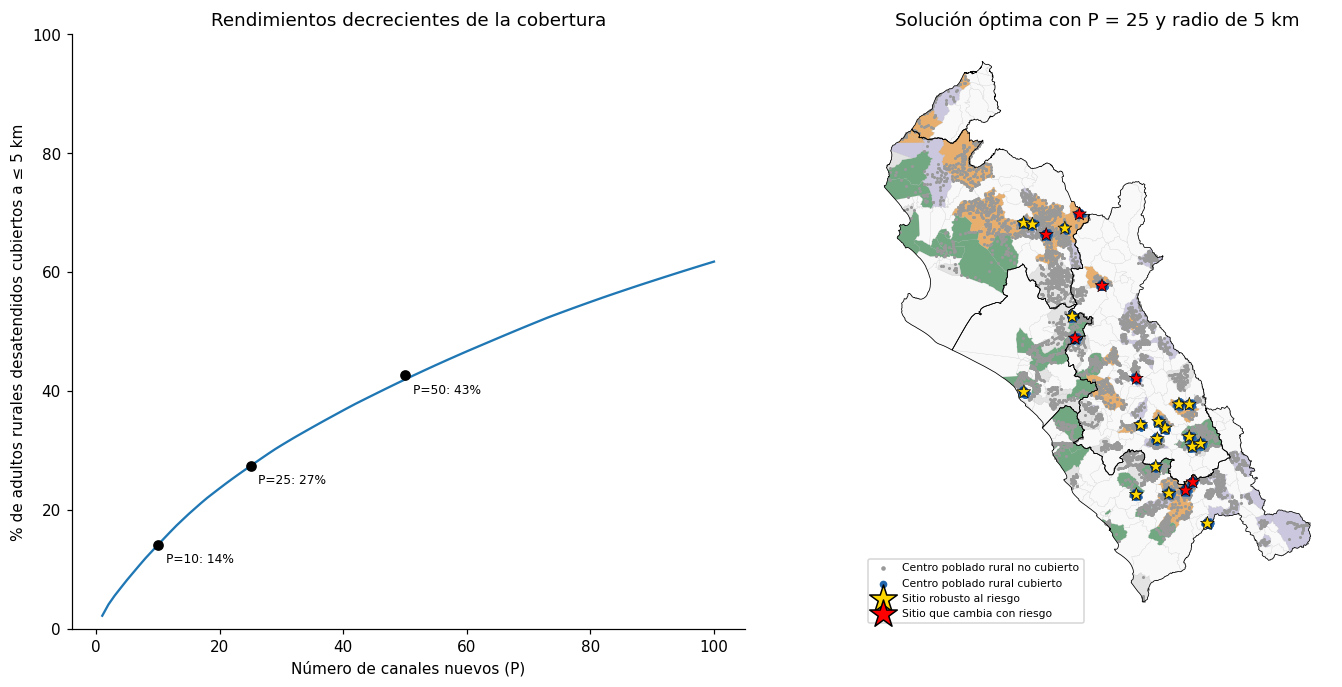

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axs[0]
ax.plot(range(1, 101), curva, color="C0")
for _, r in comparacion.iterrows():
    ax.scatter(r.P, r["cobertura_exacta_%"], color="k", zorder=3)
    ax.annotate(f"P={r.P}: {r['cobertura_exacta_%']:.0f}%", (r.P, r["cobertura_exacta_%"]), xytext=(5, -12),
                textcoords="offset points", fontsize=8)
ax.set(xlabel="Número de canales nuevos (P)", ylabel="% de adultos rurales desatendidos cubiertos a ≤ 5 km",
       title="Rendimientos decrecientes de la cobertura", ylim=(0, 100))

ax = axs[1]
distritos.plot(ax=ax, color="0.95", edgecolor="0.8", lw=0.15)
m.plot(color=m.color, ax=ax, edgecolor="0.8", lw=0.15, alpha=0.6)
departamentos.boundary.plot(ax=ax, color="k", lw=0.5)
dem = cp.demanda.values > 0
ax.scatter(XY[dem & ~cov, 0], XY[dem & ~cov, 1], s=1, c="0.6", label="Centro poblado rural no cubierto")
ax.scatter(XY[dem & cov, 0], XY[dem & cov, 1], s=4, c="#2166ac", label="Centro poblado rural cubierto")
gpd.GeoSeries(sitios.geometry.buffer(5000), crs=CRS).boundary.plot(ax=ax, color="#08306b", lw=0.9)
ax.scatter(sitios.geometry.x, sitios.geometry.y, marker="*", s=90, c=np.where(sitios.en_solucion_con_riesgo, "gold", "red"),
           edgecolor="k", lw=0.4, zorder=5)
ax.scatter([], [], marker="*", s=90, c="gold", edgecolor="k", label="Sitio robusto al riesgo")
ax.scatter([], [], marker="*", s=90, c="red", edgecolor="k", label="Sitio que cambia con riesgo")
ax.legend(fontsize=7, loc="lower left", markerscale=2)
ax.set_axis_off(); ax.set_title(f"Solución óptima con P = {P} y radio de 5 km")
plt.tight_layout(); plt.savefig(FIG / "09_mclp_cobertura.png", bbox_inches="tight"); plt.show()

In [11]:
prior = d.merge(des[["ubigeo", "oportunidad_pct", "cuadrante", "score_l0", "score_l0.5", "canales_urbanos_faltantes",
                     "adultos_rurales_desatendidos"]], on="ubigeo", how="left")
prior["sitios_mclp_P25"] = prior.ubigeo.map(sitios.ubigeo.value_counts()).fillna(0).astype(int)
prior = prior.drop(columns=["lat_capital", "lon_capital"])
prior.to_csv(DATA / "priorizacion_distrital.csv", index=False)
print(f"Distritos con al menos un sitio: {(prior.sitios_mclp_P25 > 0).sum()} | tiempo total {time.time() - t0:.0f} s")

Distritos con al menos un sitio: 23 | tiempo total 29 s


## Hallazgos

1. **Magnitud del déficit.** 147 de los 327 distritos tienen menos acceso que el esperado por su estructura. Para
   igualarlos faltan unos 9 500 canales, equivalentes a 768 mil adultos desatendidos.
2. **La mayor parte del déficit es urbano y de bajo riesgo climático.** Siete distritos urbanos (Veintiséis de
   Octubre, Pariñas, Castilla, Alto Trujillo, Chulucanas, Paita y Tambo Grande) explican la mitad del déficit de
   canales. Es un problema de **densificación** en ciudades intermedias de Piura y en Alto Trujillo, no de distancia.
3. **El riesgo cambia la prioridad, pero no la invierte.** Con el riesgo pesando la mitad que la oportunidad
   (λ = 0,5), el τ de Kendall frente al ranking sin riesgo es 0,76 y 14 de los 20 primeros distritos se mantienen.
   Hay 31 distritos de alta oportunidad y alta exposición, con 184 mil adultos desatendidos, sobre todo en la sierra
   de Piura y en el norte de Cajamarca: ahí conviene un canal que tolere interrupciones.
4. **Cobertura rural.** El problema de máxima cobertura se resuelve de forma exacta en segundos para 6 241
   candidatos. Con 25 canales nuevos se cubre el 27% de los 232 mil adultos rurales desatendidos a 5 km o menos,
   con 50 el 43% y con 100 cerca del 62%. Los rendimientos son decrecientes, y la heurística voraz queda a menos de
   un punto porcentual del óptimo en todos los casos.
5. **Dónde.** Los sitios óptimos se concentran en la sierra de Cajamarca (Llacanora, Sorochuco, Los Baños del Inca,
   San Juan), la sierra de La Libertad (Usquil, Sayapullo, Sanagorán) y la sierra de Piura (Santo Domingo, Chalaco,
   El Carmen de la Frontera). Son zonas con caseríos densos y lejos de cualquier canal.
6. **Robustez.** Al descontar la demanda por riesgo, la cobertura apenas cae (27,4% a 27,0%), 20 de 25 sitios quedan
   a 5 km o menos de un sitio de la solución base y los sitios en zonas de riesgo alto bajan de 8 a 5. El radio sí
   importa: con 10 km la cobertura sube a 50% y la red se reorganiza (15 de 25 sitios cerca de los de 5 km), por lo
   que el radio debe fijarse según el tipo de canal (agente a pie frente a agencia con transporte).

**Limitaciones.** La demanda dentro del distrito se reparte en partes iguales entre caseríos porque la base no trae
población por centro poblado; la distancia es en línea recta y no por red vial; el acceso esperado proviene de un
modelo con R² = 0,33 en validación espacial, por lo que la brecha de cada distrito tiene incertidumbre.

## Referencias

* Church, R., & ReVelle, C. (1974). The maximal covering location problem. *Papers of the Regional Science Association, 32*(1), 101-118.
* Nemhauser, G. L., Wolsey, L. A., & Fisher, M. L. (1978). An analysis of approximations for maximizing submodular set functions. *Mathematical Programming, 14*(1), 265-294.
* Murray, A. T. (2016). Maximal coverage location problem: Impacts, significance, and evolution. *International Regional Science Review, 39*(1), 5-27.